# **Experiment 7: Logical and Probabilistic Reasoning**

In [ ]:
#1. Propositional Logic

import pandas as pd
from itertools import product

# P = It rains
# Q = The road is wet

def implication(P, Q):
    return (not P) or Q

truth_table = []

for P, Q in product([True, False], repeat=2):
    truth_table.append({
        "It Rains (P)": P,
        "Road is Wet (Q)": Q,
        "P -> Q": implication(P, Q)
    })

df = pd.DataFrame(truth_table)
print(df)

   It Rains (P)  Road is Wet (Q)  P -> Q
0          True             True    True
1          True            False   False
2         False             True    True
3         False            False    True


In [ ]:
#2. First-Order Logic

# Facts and rules

humans = {"Socrates", "Plato", "Aristotle"}

def is_human(person):
    return person in humans

def is_mortal(person):
    # Rule: All humans are mortal
    if is_human(person):
        return True
    return False

person = "Socrates"

print("Is Socrates human?", is_human(person))
print("Is Socrates mortal?", is_mortal(person))

if is_human(person) and is_mortal(person):
    print("Conclusion: Socrates is mortal.")

Is Socrates human? True
Is Socrates mortal? True
Conclusion: Socrates is mortal.


In [ ]:
#3. Probability of Events

import pandas as pd

data = {
    "Student": ["S1", "S2", "S3", "S4", "S5",
                "S6", "S7", "S8", "S9", "S10"],
    "Attendance": ["Yes", "Yes", "Yes", "Yes", "Yes",
                   "No", "No", "Yes", "No", "Yes"],
    "Result": ["Pass", "Pass", "Pass", "Fail", "Pass",
               "Fail", "Pass", "Fail", "Fail", "Pass"]
}

df = pd.DataFrame(data)

total = len(df)

A = df["Attendance"] == "Yes"
B = df["Result"] == "Pass"

p_A = A.sum() / total
p_B = B.sum() / total
p_A_and_B = (A & B).sum() / total
p_A_or_B = p_A + p_B - p_A_and_B

print("P(A) - Attendance:", p_A)
print("P(B) - Pass:", p_B)
print("P(A ∩ B) - Attendance and Pass:", p_A_and_B)
print("P(A ∪ B) - Attendance or Pass:", p_A_or_B)

P(A) - Attendance: 0.7
P(B) - Pass: 0.6
P(A ∩ B) - Attendance and Pass: 0.5
P(A ∪ B) - Attendance or Pass: 0.7999999999999998


In [ ]:
#4. Conditional Probability


p_A_given_B = (A & B).sum() / B.sum()
p_B_given_A = (A & B).sum() / A.sum()

print("P(A | B) - Attended given Pass:", p_A_given_B)
print("P(B | A) - Pass given Attendance:", p_B_given_A)

P(A | B) - Attended given Pass: 0.8333333333333334
P(B | A) - Pass given Attendance: 0.7142857142857143


In [ ]:
#5. Bayes' Theorem

# Prior probabilities
p_disease = 0.01
p_positive_given_disease = 0.90
p_positive_given_no_disease = 0.05

p_no_disease = 1 - p_disease

# Total probability of a positive test
p_positive = (
    p_positive_given_disease * p_disease
    + p_positive_given_no_disease * p_no_disease
)

# Bayes' theorem
p_disease_given_positive = (
    p_positive_given_disease * p_disease / p_positive
)

print("P(Positive Test):", p_positive)
print("P(Disease | Positive Test):", p_disease_given_positive)
print("Percentage:", p_disease_given_positive * 100, "%")

P(Positive Test): 0.0585
P(Disease | Positive Test): 0.15384615384615385
Percentage: 15.384615384615385 %


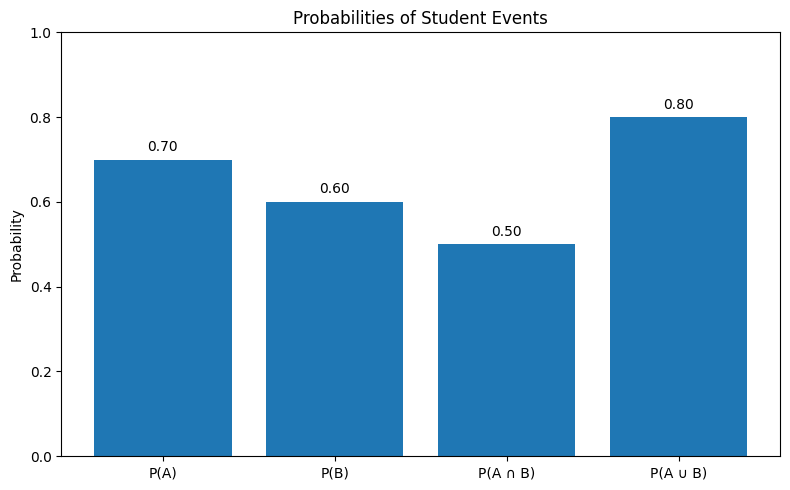

In [ ]:
import matplotlib.pyplot as plt

labels = ["P(A)", "P(B)", "P(A ∩ B)", "P(A ∪ B)"]
values = [p_A, p_B, p_A_and_B, p_A_or_B]

plt.figure(figsize=(8, 5))
bars = plt.bar(labels, values)

plt.ylim(0, 1)
plt.ylabel("Probability")
plt.title("Probabilities of Student Events")

for bar, value in zip(bars, values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.02,
        f"{value:.2f}",
        ha="center"
    )

plt.tight_layout()
plt.show()

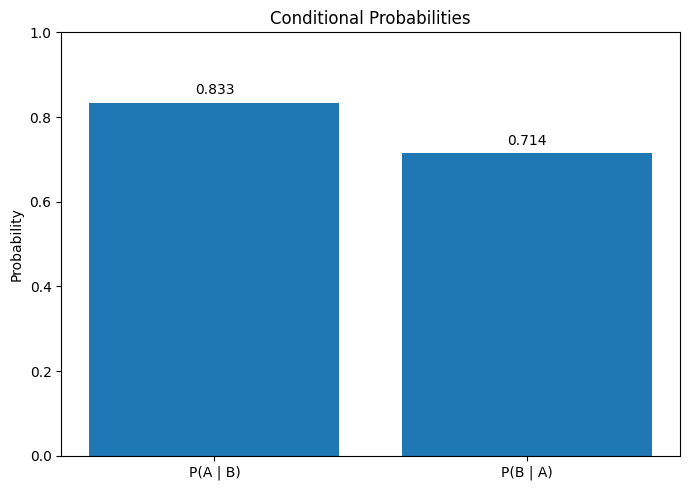

In [ ]:
labels = ["P(A | B)", "P(B | A)"]
values = [p_A_given_B, p_B_given_A]

plt.figure(figsize=(7, 5))
bars = plt.bar(labels, values)

plt.ylim(0, 1)
plt.ylabel("Probability")
plt.title("Conditional Probabilities")

for bar, value in zip(bars, values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.02,
        f"{value:.3f}",
        ha="center"
    )

plt.tight_layout()
plt.show()

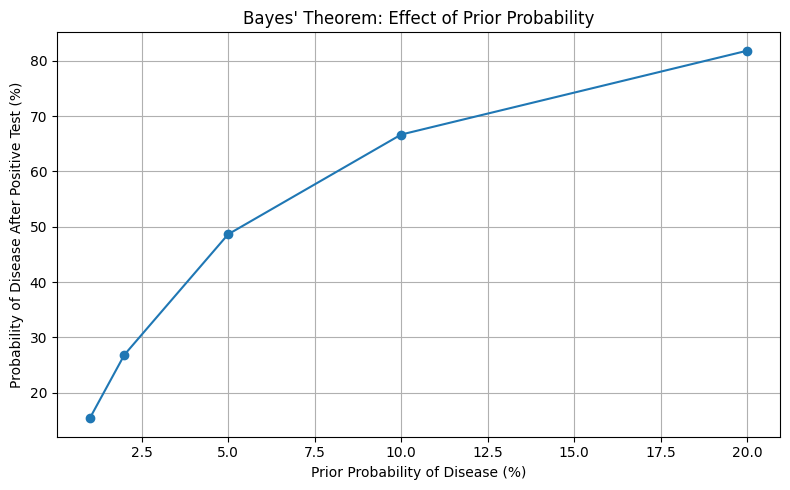

Prior: 1% -> Posterior after positive test: 15.38%
Prior: 2% -> Posterior after positive test: 26.87%
Prior: 5% -> Posterior after positive test: 48.65%
Prior: 10% -> Posterior after positive test: 66.67%
Prior: 20% -> Posterior after positive test: 81.82%


In [ ]:
import matplotlib.pyplot as plt

prior_probabilities = [
    0.01, 0.02, 0.05, 0.10, 0.20
]

posterior_probabilities = []

sensitivity = 0.90
false_positive_rate = 0.05

for prior in prior_probabilities:
    p_positive = (
        sensitivity * prior
        + false_positive_rate * (1 - prior)
    )

    posterior = sensitivity * prior / p_positive
    posterior_probabilities.append(posterior)

plt.figure(figsize=(8, 5))
plt.plot(
    [p * 100 for p in prior_probabilities],
    [p * 100 for p in posterior_probabilities],
    marker="o"
)

plt.xlabel("Prior Probability of Disease (%)")
plt.ylabel("Probability of Disease After Positive Test (%)")
plt.title("Bayes' Theorem: Effect of Prior Probability")
plt.grid(True)
plt.tight_layout()
plt.show()

for prior, posterior in zip(
    prior_probabilities, posterior_probabilities
):
    print(
        f"Prior: {prior:.0%} -> "
        f"Posterior after positive test: {posterior:.2%}"
    )